# Slides under a magnifying glass: a VLM with crop and zoom

A small VLM (Qwen3-VL-4B-Instruct) answers questions about presentation slides that need small details: a label, a value on a chart, how blocks connect. We give it a crop/zoom tool and let it choose regions. We compare six ways of looking at a slide and study when zoom helps and where it fails.

| Mode | What the model sees |
|---|---|
| A | full slide, low visual-token budget, no zoom |
| B | full slide, high budget (upscaled to the budget), no zoom |
| C | low-budget overview plus 4 tiles (2x2, 10% overlap) cut from the original, one query |
| D | agent: low-budget overview, then the model requests crops from the original (up to 3) |
| E | ablation of D: the model must propose exactly one box before answering |
| F | control for the answer format: same view as A, but the answer is requested as a JSON object, as in D and E |

B shows whether zoom is needed at all or a bigger picture is enough. C is the fixed-crop baseline.

Budgets: the overview uses 256 visual tokens (a token is about 32x32 px), the high budget is 1500 tokens. Source slides are 1024 px on the long side.

Design assumptions: the model gets only the evidence slide, never the whole deck. A, B and C ask for a plain short answer; D and E use a JSON protocol (zoom or answer), so format handling differs between the two groups.

## 1. Setup: imports, model and folders

Switch `BACKEND_KIND` between `'mlx'` (the real model on the Mac) and `'mock'` (scripted replies that test the pipeline without a model). `DATA_ROOT` and `RESULTS` set where slides and result files live. Nothing is computed in this section.

In [1]:
import json
import os
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

import agent
import data
import demo
import metrics
import tools
from backend import MockBackend, make_backend

BACKEND_KIND = 'mlx'
MODEL_IDS = {'mlx': 'mlx-community/Qwen3-VL-4B-Instruct-4bit', 'transformers': 'Qwen/Qwen3-VL-4B-Instruct'}
DATA_ROOT = 'data'
RESULTS = 'results'
os.makedirs(RESULTS, exist_ok=True)

## 2. Data: 400 SlideVQA questions, each with its evidence slide

The pool comes from the SlideVQA test split: one evidence page per question, answers of at most five words, at most two questions per deck. Questions are not chosen by model errors. `splits.json` fixes 30 dev and 120 test questions once, balanced between numeric and text answers, and is never changed afterwards. If `data/pool.jsonl` is missing, synthetic bar-chart slides are used instead (results on them mean nothing).

The size check at the end shows that slides are 1024 px on the long side, below the 1400 px we wanted, so zoom cannot reveal detail beyond the original.

In [2]:
POOL = os.path.join(DATA_ROOT, 'pool.jsonl')
if os.path.exists(POOL):
    ITEMS = data.read_pool(POOL)
    N_DEV, N_TEST, SPLITS_PATH = 30, 120, 'splits.json'
else:
    DATA_ROOT = 'data_mock'
    ITEMS = data.make_synthetic(DATA_ROOT, n=40)
    N_DEV, N_TEST, SPLITS_PATH = 10, 30, 'splits_mock.json'
    print('pool not found, using synthetic slides')
SPLITS = data.make_splits(ITEMS, SPLITS_PATH, N_DEV, N_TEST)
DEV, TEST = (data.get_split(ITEMS, SPLITS, k) for k in ('dev', 'test'))
stats = data.size_stats(ITEMS, DATA_ROOT)
print(len(ITEMS), 'in pool,', len(DEV), 'dev,', len(TEST), 'test')
print('longest side, px:', stats)
if not stats['zoom_has_headroom']:
    print('median longest side is below 1400 px: a high-budget full view may already show everything; consider InfographicVQA')
pd.Series([data.answer_kind(it) for it in ITEMS]).value_counts()

400 in pool, 30 dev, 120 test
longest side, px: {'n': 400, 'p10': 1024, 'median': 1024, 'p90': 1024, 'zoom_has_headroom': False}
median longest side is below 1400 px: a high-budget full view may already show everything; consider InfographicVQA


text      284
number    116
Name: count, dtype: int64

## 3. Backend and smoke test: loading the model and checking box coordinates

The backend is one function, `generate(messages, images)`, with MLX, transformers and mock implementations. The mock answers from the gold labels with fixed probabilities, so its numbers only test the code.

In [3]:
class Mock:
    def __init__(self, items, seed=0):
        self.gold = {it['question']: it['answers'][0] for it in items}
        self.rng = random.Random(seed)

    def __call__(self, messages, images):
        parts = [p.get('text', '') for m in messages for p in m['content']]
        text = ' '.join(parts)
        q = next(re.search(r'Question: (.*)', t).group(1) for t in parts if 'Question: ' in t)
        json_mode = 'exactly one JSON object' in text
        if json_mode:
            if len(images) == 1 and self.rng.random() < 0.8:
                x, y = self.rng.randint(0, 300), self.rng.randint(0, 300)
                return json.dumps({'action': 'zoom', 'box': [x, y, x + self.rng.randint(250, 600), y + self.rng.randint(250, 600)]})
            p = 0.8 if len(images) > 1 else 0.5
        else:
            p = 0.7 if len(images) == 5 else 0.5
        ans = self.gold[q] if self.rng.random() < p else '0'
        return json.dumps({'action': 'answer', 'answer': ans}) if json_mode else ans


if BACKEND_KIND == 'mock':
    BACKEND = MockBackend(Mock(ITEMS))
else:
    BACKEND = make_backend(BACKEND_KIND, model_id=MODEL_IDS[BACKEND_KIND])
agent.set_backend(BACKEND)
TAG = BACKEND_KIND

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

### Smoke test

Five dev questions in mode D. Each box must sit on the region the question is about; a wrong scale or a shifted origin shows up as boxes on empty areas. The last cell compares the visual tokens we expect with the count the backend reports.

359 | What is the formula for NPS?
1. box=[262.0, 156.0, 728.0, 286.0] ok
   raw: {"action": "zoom", "box": [262, 156, 728, 286]}
answer: 'NPS = % Promoters - % Detractors'
gold: ['% Promoters - % Detractors']
tokens: 1184, seconds: 6.85

842 | How many ways are identified for achieving the goal of attention attraction and retention?
1. box=[400.0, 202.0, 966.0, 572.0] ok
   raw: {"action": "zoom", "box": [400, 202, 966, 572]}
answer: '7'
gold: ['7']
tokens: 1708, seconds: 9.02

990 | In Oceania in January 2014, how many more Internet users were there than active social network users?
1. box=[175.0, 222.0, 542.0, 486.0] ok
   raw: {"action": "zoom", "box": [175, 222, 542, 486]}  {"action": "answer", "answer": 4222226}
2. box=[100.0, 622.0, 600.0, 927.0] ok
   raw: {"action": "zoom", "box": [100, 622, 600, 927]}  {"action": "answer", "answer": "1,399,000"}
3. box=[100.0, 362.0, 595.0, 632.0] ok
   raw: {"action": "zoom", "box": [100.0, 362.0, 595.0, 632.0]}
answer: '6,862,268'
gold: ['6

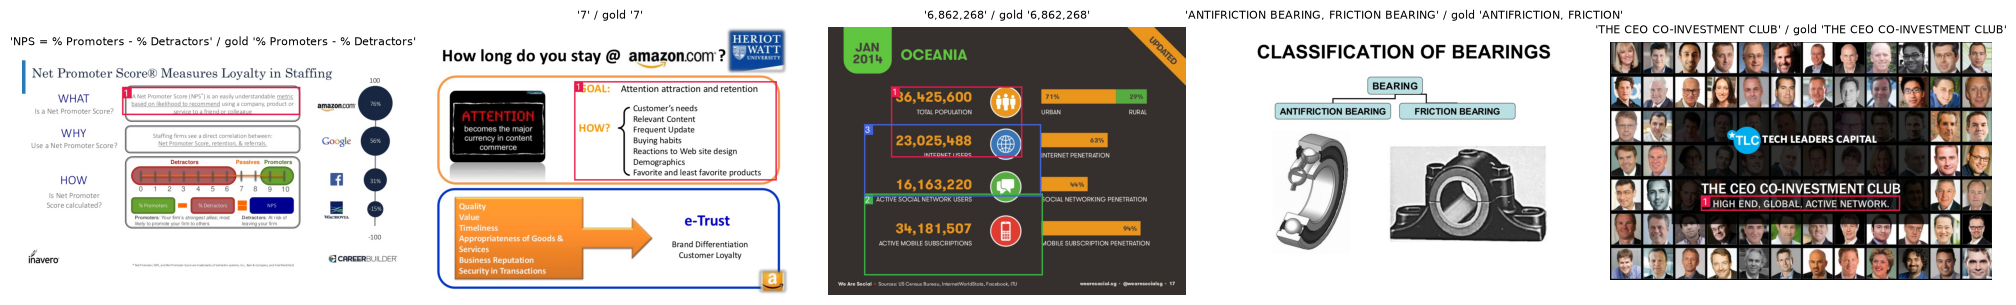

In [4]:
SMOKE = DEV[:5]
fig, axes = plt.subplots(1, len(SMOKE), figsize=(4 * len(SMOKE), 3))
for ax, it in zip(np.atleast_1d(axes), SMOKE):
    im = Image.open(os.path.join(DATA_ROOT, it['image'])).convert('RGB')
    rec = agent.run(im, it['question'], 'D')
    rec['id'], rec['gold'] = it['id'], it['answers']
    shown, gallery, log = demo.explain(im, rec)
    print(it['id'], '|', it['question'])
    print(log)
    print()
    ax.imshow(shown)
    ax.axis('off')
    ax.set_title(f"{rec['answer']!r} / gold {it['answers'][0]!r}", fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
im = Image.open(os.path.join(DATA_ROOT, SMOKE[0]['image'])).convert('RGB')
rec = agent.run(im, SMOKE[0]['question'], 'A')
print('expected visual tokens:', tools.visual_tokens(tools.fit(im, agent.CFG['low'])), '| tokens reported by backend (visual + text + output):', rec['tokens'])

expected visual tokens: 252 | tokens reported by backend (visual + text + output): 309


## 4. Runs: six viewing modes on 120 test questions

Every mode answers every question. Each answer is appended to a jsonl file as soon as it is finished and finished ids are skipped on restart, so any cell can be interrupted and run again. Dev is for checking prompts and code; test gives all reported numbers.

In [6]:
for m in 'ABCDEF':
    agent.run_dataset(DEV, m, f'{RESULTS}/{TAG}_dev.jsonl', root=DATA_ROOT)

mode F: 10/30
mode F: 20/30
mode F: 30/30


In [7]:
for m in 'ABCDEF':
    agent.run_dataset(TEST, m, f'{RESULTS}/{TAG}_test.jsonl', root=DATA_ROOT)

### Overview-budget control runs

The agent's overview has 256 visual tokens. Two extra runs with 768 tokens test whether a better first look lets it catch up with B: mode D (agent) and mode A (same overview, no zoom). The second run separates the effect of zoom from the effect of a bigger overview. Each run writes to its own file, and the budget returns to 256 afterwards. Set the flag to `False` to skip a run.

In [8]:
RUN_D768 = True
if RUN_D768:
    agent.CFG['low'] = 768
    try:
        agent.run_dataset(TEST, 'D', f'{RESULTS}/{TAG}_test_low768.jsonl', root=DATA_ROOT)
    finally:
        agent.CFG['low'] = 256

In [9]:
RUN_A768 = True
if RUN_A768:
    agent.CFG['low'] = 768
    try:
        agent.run_dataset(TEST, 'A', f'{RESULTS}/{TAG}_test_low768_A.jsonl', root=DATA_ROOT)
    finally:
        agent.CFG['low'] = 256

mode A: 10/120
mode A: 20/120
mode A: 30/120
mode A: 40/120
mode A: 50/120
mode A: 60/120
mode A: 70/120
mode A: 80/120
mode A: 90/120
mode A: 100/120
mode A: 110/120
mode A: 120/120


## 5. Results: accuracy, cost and where zoom helps

Exact match (EM) counts an answer as right only if it equals the gold answer after normalisation (case, thousands commas, articles); F1 gives partial credit for shared words. Intervals are 95% bootstrap intervals: the 120 questions are resampled 2000 times. With 120 questions an accuracy near 0.6 has an interval of about plus or minus 9 points, so small differences are not effects.

### 5.1 Accuracy and cost by mode

In [10]:
RECS = {m: [r for r in agent.read_jsonl(f'{RESULTS}/{TAG}_test.jsonl') if r['mode'] == m] for m in 'ABCDEF'}
SCORES = {m: metrics.score(r) for m, r in RECS.items() if r}
table = pd.DataFrame(SCORES).T
table['em (95% ci)'] = [f"{s['em']:.2f} {s['em_ci']}" for s in SCORES.values()]
table['f1 (95% ci)'] = [f"{s['f1']:.2f} {s['f1_ci']}" for s in SCORES.values()]
table[['n', 'em (95% ci)', 'f1 (95% ci)', 'zoom_rate', 'mean_zooms', 'format_errors', 'tokens', 'seconds', 'num_5pct']]

,n,em (95% ci),f1 (95% ci),zoom_rate,mean_zooms,format_errors,tokens,seconds,num_5pct
A,120,"0.66 [0.575, 0.7417]","0.73 [0.657, 0.8039]",0.0,0.0,0.0,309.4,1.55,0.7969
B,120,"0.82 [0.75, 0.8833]","0.86 [0.8015, 0.914]",0.0,0.0,0.0,1583.5,10.89,0.8571
C,120,"0.75 [0.6667, 0.825]","0.83 [0.7645, 0.8881]",0.0,0.0,0.0,5003.2,36.64,0.9016
D,120,"0.66 [0.575, 0.7417]","0.74 [0.6651, 0.8094]",0.8417,0.91,0.0,1770.4,12.78,0.8361
E,120,"0.63 [0.55, 0.7167]","0.74 [0.6727, 0.8062]",0.9917,0.99,0.0,1737.4,11.71,0.85
F,120,"0.66 [0.575, 0.7417]","0.72 [0.647, 0.7993]",0.0,0.0,0.0,335.9,2.08,0.8226


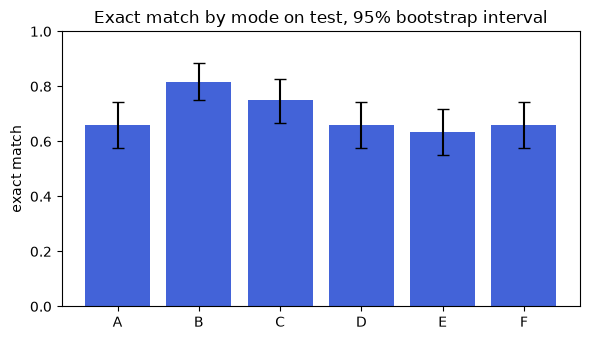

In [11]:
modes = list(SCORES)
em_m = [SCORES[m]['em'] for m in modes]
err = [[SCORES[m]['em'] - SCORES[m]['em_ci'][0] for m in modes], [SCORES[m]['em_ci'][1] - SCORES[m]['em'] for m in modes]]
plt.figure(figsize=(6, 3.5))
plt.bar(modes, em_m, yerr=err, capsize=4, color='#4363d8')
plt.ylim(0, 1)
plt.ylabel('exact match')
plt.title('Exact match by mode on test, 95% bootstrap interval')
plt.tight_layout()
plt.show()

Real run (Qwen3-VL-4B, 4-bit, 120 test questions): B, the whole slide at 1500 tokens, is the most accurate (EM 0.82 against 0.66 for A). The agent (D) equals A and F at 0.66 but uses about five times as many tokens. C reaches 0.75 and needs about 5000 tokens per question.

### 5.2 Paired comparisons between modes

Same questions, two modes: a bootstrap interval for the difference in EM and F1 (second mode minus first) and an exact McNemar test on EM, which looks only at questions where the two modes disagree. A to F shows whether the answer format matters; F to D is the effect of zoom at the same format.

In [12]:
PAIRS = [('A', 'B'), ('A', 'C'), ('A', 'D'), ('A', 'F'), ('F', 'D'), ('B', 'D'), ('C', 'D'), ('D', 'E')]
rows = []
for a, b in PAIRS:
    if RECS[a] and RECS[b]:
        rows.append({'pair': f'{a} -> {b}', **metrics.compare(RECS[a], RECS[b])})
pd.DataFrame(rows).set_index('pair')

,n,d_em,d_em_ci,d_f1,d_f1_ci,only_a,only_b,mcnemar_p
pair,,,,,,,,
A -> B,120,0.1583,"[0.0917, 0.225]",0.1290,"[0.0731, 0.191]",0,19,0.0000
A -> C,120,0.0917,"[0.025, 0.1583]",0.0998,"[0.0409, 0.1621]",3,14,0.0127
A -> D,120,0.0000,"[-0.0667, 0.0667]",0.0084,"[-0.0454, 0.0623]",8,8,1.0000
A -> F,120,0.0000,"[-0.0333, 0.0333]",-0.0060,"[-0.0283, 0.0112]",2,2,1.0000
F -> D,120,0.0000,"[-0.0583, 0.0583]",0.0144,"[-0.0392, 0.0704]",7,7,1.0000
B -> D,120,-0.1583,"[-0.225, -0.0917]",-0.1206,"[-0.1806, -0.0619]",20,1,0.0000
C -> D,120,-0.0917,"[-0.1667, -0.025]",-0.0915,"[-0.1535, -0.0308]",16,5,0.0266
D -> E,120,-0.0250,"[-0.0833, 0.0333]",0.0013,"[-0.0429, 0.0458]",8,5,0.5811


B beats A by 16 points (19 questions against 0). D against A or F is 0.00 with an interval of about plus or minus 6 points (8 against 8, 7 against 7), so no effect of zoom is detected, and the answer format does not matter (A against F: 2 against 2). D is 16 points below B at a similar cost. With eight comparisons a strict threshold is about p < 0.006, which only A to B and B to D clear.

### 5.3 Where zoom helps: answer type and zoom usage

EM by answer type for A, B, D and F, and D split by whether the model zoomed. The second split is not a causal estimate: the model chooses when to zoom, so the questions differ between the groups.

In [13]:
KIND = {it['id']: data.answer_kind(it) for it in ITEMS}
rows = []
for m in 'ABDF':
    for r in RECS[m]:
        rows.append({'mode': m, 'kind': KIND[r['id']], 'em': metrics.em(r['answer'], r['gold'])})
display(pd.DataFrame(rows).groupby(['kind', 'mode'])['em'].agg(['mean', 'count']).round(2))
used = {r['id']: metrics.valid_zooms(r) > 0 for r in RECS['D']}
a_em = {r['id']: metrics.em(r['answer'], r['gold']) for r in RECS['A']}
d_em = {r['id']: metrics.em(r['answer'], r['gold']) for r in RECS['D']}
display(pd.DataFrame([{'D zoomed': z, 'n': sum(1 for i in used if used[i] == z), 'em A': round(np.mean([a_em[i] for i in used if used[i] == z]), 2), 'em D': round(np.mean([d_em[i] for i in used if used[i] == z]), 2)} for z in (False, True) if any(v == z for v in used.values())]))

mean  count
kind   mode             
number A     0.75     60
       B     0.85     60
       D     0.70     60
       F     0.72     60
text   A     0.57     60
       B     0.78     60
       D     0.62     60
       F     0.60     60

,D zoomed,n,em A,em D
0,False,19,0.89,0.89
1,True,101,0.61,0.61


Text answers gain the most from a bigger view (B 0.78 against 0.57 for A), numbers less (0.85 against 0.75); each group has 60 questions, so intervals are about plus or minus 12 points. D does not zoom on 19 of 120 questions; on these A and D both reach 0.89, against 0.61 on the 101 zoomed ones. The model skips zoom mostly on easy questions.

### 5.4 Overview budget: 256 vs 768 tokens

Does a better first look let the agent catch up with B? D with a 768-token overview is compared with the same overview without zoom (A at 768), which separates the effect of zoom from the effect of a bigger overview.

In [14]:
R768 = agent.read_jsonl(f'{RESULTS}/{TAG}_test_low768.jsonl')
RA768 = agent.read_jsonl(f'{RESULTS}/{TAG}_test_low768_A.jsonl')
rows = {'A (256)': RECS['A'], 'A (768, no zoom)': RA768, 'D (overview 256)': RECS['D'], 'D (overview 768)': R768, 'B': RECS['B']}
sc = {k: metrics.score(v) for k, v in rows.items()}
t = pd.DataFrame(sc).T
t['em (95% ci)'] = [f"{s['em']:.2f} {s['em_ci']}" for s in sc.values()]
t['f1 (95% ci)'] = [f"{s['f1']:.2f} {s['f1_ci']}" for s in sc.values()]
display(t[['n', 'em (95% ci)', 'f1 (95% ci)', 'zoom_rate', 'mean_zooms', 'tokens', 'seconds']])
pairs = [('A (256)', 'A (768, no zoom)'), ('A (768, no zoom)', 'D (overview 768)'), ('D (overview 256)', 'D (overview 768)'), ('A (768, no zoom)', 'B'), ('B', 'D (overview 768)')]
display(pd.DataFrame([{'pair': f'{a} -> {b}', **metrics.compare(rows[a], rows[b])} for a, b in pairs]).set_index('pair'))

,n,em (95% ci),f1 (95% ci),zoom_rate,mean_zooms,tokens,seconds
A (256),120,"0.66 [0.575, 0.7417]","0.73 [0.657, 0.8039]",0.0,0.0,309.4,1.55
"A (768, no zoom)",120,"0.79 [0.7167, 0.8583]","0.87 [0.8135, 0.9188]",0.0,0.0,799.4,4.55
D (overview 256),120,"0.66 [0.575, 0.7417]","0.74 [0.6651, 0.8094]",0.8417,0.91,1770.4,12.78
D (overview 768),120,"0.71 [0.625, 0.7833]","0.80 [0.7344, 0.859]",0.8667,0.89,2664.3,18.51
B,120,"0.82 [0.75, 0.8833]","0.86 [0.8015, 0.914]",0.0,0.0,1583.5,10.89


,n,d_em,d_em_ci,d_f1,d_f1_ci,only_a,only_b,mcnemar_p
pair,,,,,,,,
"A (256) -> A (768, no zoom)",120,0.1333,"[0.075, 0.2]",0.1372,"[0.0824, 0.1964]",0,16,0.0000
"A (768, no zoom) -> D (overview 768)",120,-0.0833,"[-0.1417, -0.025]",-0.0675,"[-0.115, -0.0221]",12,2,0.0129
D (overview 256) -> D (overview 768),120,0.0500,"[0.0, 0.1]",0.0613,"[0.0135, 0.1111]",2,8,0.1094
"A (768, no zoom) -> B",120,0.0250,"[-0.0083, 0.0583]",-0.0082,"[-0.0351, 0.0189]",1,4,0.3750
B -> D (overview 768),120,-0.1083,"[-0.1667, -0.05]",-0.0593,"[-0.1087, -0.0125]",14,1,0.0010


D with a 768-token overview reaches EM 0.71, 5 points above D at 256 tokens (interval 0 to +10). The same overview without zoom (A at 768 tokens) reaches 0.79 at about 800 tokens per question: 8 points above D at 768 (interval -14 to -3, 12 questions against 2) and within 3 points of B. A 1024x768 slide costs exactly 768 tokens at native resolution, so at this budget nothing is lost by downscaling and zoom has nothing to recover. Here zoom only adds cost and loses accuracy.

### 5.5 Accuracy against cost for all modes

Each point is one mode on the 120 test questions. The horizontal axis is the mean number of tokens per question (image, text and generated), the vertical axis is exact match, and the vertical bar is the 95% bootstrap interval. The dashed line joins the modes that no other mode beats at equal or lower cost.

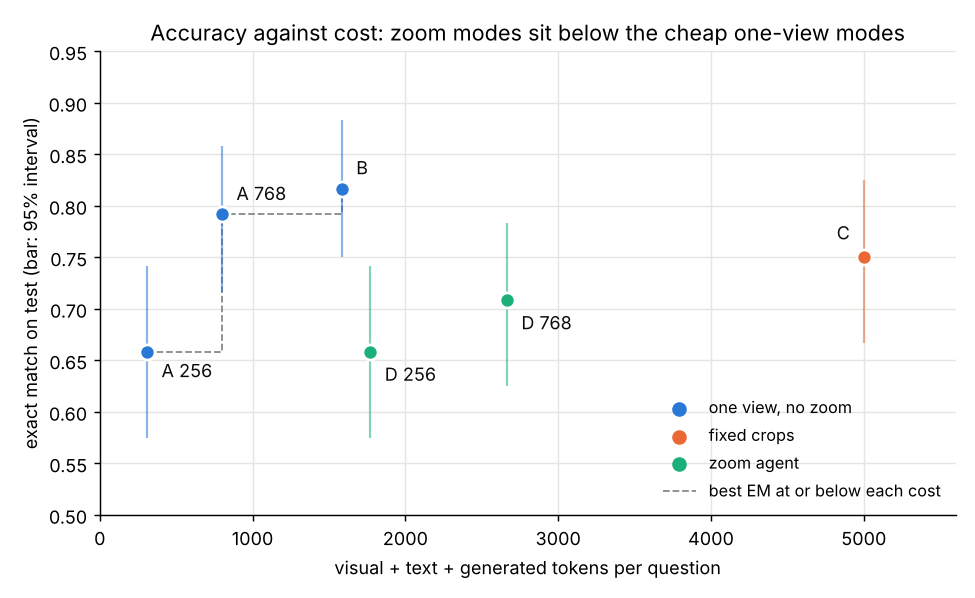

                  family  tokens    em    lo    hi
mode                                              
A 256  one view, no zoom   309.4  0.66  0.57  0.74
A 768  one view, no zoom   799.4  0.79  0.72  0.86
B      one view, no zoom  1583.5  0.82  0.75  0.88
C            fixed crops  5003.2  0.75  0.67  0.82
D 256         zoom agent  1770.4  0.66  0.57  0.74
D 768         zoom agent  2664.3  0.71  0.62  0.78

In [ ]:
FRONT = [
    ('A 256', RECS['A'], 'one view, no zoom', (8, -14)),
    ('A 768', RA768, 'one view, no zoom', (8, 8)),
    ('B', RECS['B'], 'one view, no zoom', (8, 8)),
    ('C', RECS['C'], 'fixed crops', (-8, 10)),
    ('D 256', RECS['D'], 'zoom agent', (8, -16)),
    ('D 768', R768, 'zoom agent', (8, -16)),
]
FAMILY = {'one view, no zoom': '#2a78d6', 'fixed crops': '#eb6834', 'zoom agent': '#1baf7a'}
pts = []
for name, recs, fam, off in FRONT:
    s = metrics.score(recs)
    pts.append({'mode': name, 'family': fam, 'tokens': s['tokens'], 'em': s['em'], 'lo': s['em_ci'][0], 'hi': s['em_ci'][1], 'off': off})
frontier = [p for p in pts if not any(q['tokens'] <= p['tokens'] and q['em'] >= p['em'] and (q['tokens'], q['em']) != (p['tokens'], p['em']) for q in pts)]
frontier.sort(key=lambda p: p['tokens'])

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.step([p['tokens'] for p in frontier], [p['em'] for p in frontier], where='post', color='#8a8985', lw=1, ls='--', zorder=1)
for p in pts:
    c = FAMILY[p['family']]
    ax.errorbar(p['tokens'], p['em'], yerr=[[p['em'] - p['lo']], [p['hi'] - p['em']]], fmt='none', ecolor=c, elinewidth=1.2, alpha=0.55, capsize=0, zorder=2)
    ax.scatter(p['tokens'], p['em'], s=70, color=c, edgecolor='white', linewidth=1.5, zorder=3)
    ha = 'left' if p['off'][0] > 0 else 'right'
    ax.annotate(p['mode'], (p['tokens'], p['em']), xytext=p['off'], textcoords='offset points', ha=ha, fontsize=10, color='#0b0b0b')
for fam, c in FAMILY.items():
    ax.scatter([], [], s=50, color=c, label=fam)
ax.plot([], [], color='#8a8985', lw=1, ls='--', label='best EM at or below each cost')
ax.set_xlabel('visual + text + generated tokens per question')
ax.set_ylabel('exact match on test (bar: 95% interval)')
ax.set_ylim(0.5, 0.95)
ax.set_xlim(0, 5600)
ax.grid(color='#e6e5e1', lw=0.8)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc='lower right', fontsize=9)
ax.set_title('Accuracy against cost: zoom modes sit below the cheap one-view modes')
plt.tight_layout()
plt.show()
display(pd.DataFrame(pts).drop(columns='off').set_index('mode').round(2))

Three modes lie on the dashed line: A at 256 tokens (EM 0.66, 309 tokens), A at 768 tokens (0.79, 799 tokens) and B (0.82, 1584 tokens). Going from 256 to 768 tokens buys 13 points for about 490 more tokens. Going from 768 to 1500 buys 2.5 more points for about 780 more tokens, and that gap is inside the noise (p = 0.375 in 5.4).

Both agent runs sit below the line. D at 256 tokens costs 1770 tokens and scores 0.66, the same as A at 256, which costs 309. D at 768 costs 2664 tokens and scores 0.71, 8 points under A at 768. C, the fixed 2x2 tiles, costs 5003 tokens and reaches 0.75, no more than a single native-resolution view in this sample.

The intervals overlap for most pairs, so the order inside the group A 768, B, C and D 768 is not established. The clear results are A at 256 below A at 768 and B, and D at 768 below A at 768. On SlideVQA, whose slides are 1024 px wide, a bigger single view is the cheapest way to gain accuracy and zoom is not on the efficient frontier.

## 6. Own questions

15 questions on course slides: 5 per detail type (axis label, value on a chart, small text, relation between blocks). Put slide images into `own_slides/` and fill `own_slides/questions.csv` (several accepted answers separated by `;`).

In [15]:
OWN_CSV = data.make_own_template('own_slides/questions.csv')
OWN = data.load_own(OWN_CSV)
print(len(OWN), 'own questions filled')
if OWN:
    for m in 'ABCDEF':
        agent.run_dataset(OWN, m, f'{RESULTS}/{TAG}_own.jsonl', root='own_slides')
    own = [agent.read_jsonl(f'{RESULTS}/{TAG}_own.jsonl')]
    rows = [{'mode': r['mode'], 'type': next(o['detail_type'] for o in OWN if o['id'] == r['id']), 'em': metrics.em(r['answer'], r['gold'])} for r in own[0]]
    display(pd.DataFrame(rows).groupby(['type', 'mode'])['em'].mean().unstack().round(2))

0 own questions filled


## 7. Error analysis

The table has the errors of mode D and of mode A (up to 30 each, sampled with a fixed seed). For every error there is a montage image: the slide with numbered boxes and the crops the model saw. The `category` column is empty and is filled by hand. Categories:

1. zoom not requested when needed
2. wrong region
3. right region, misread text
4. correct in meaning but format mismatch (counted separately as a metric error)
5. needs reasoning or several slides

`f1` and `num_5pct` are hints for category 4 only.

In [16]:
def error_rows(mode, k=30, seed=0):
    wrong = [r for r in RECS[mode] if metrics.em(r['answer'], r['gold']) == 0]
    random.Random(seed).shuffle(wrong)
    out = []
    for r in wrong[:k]:
        it = next(x for x in ITEMS if x['id'] == r['id'])
        im = Image.open(os.path.join(DATA_ROOT, it['image'])).convert('RGB')
        path = demo.montage(im, r, f'errors/{TAG}_{mode}_{r["id"]}.png')
        out.append({'id': r['id'], 'mode': mode, 'question': r['question'], 'gold': ' | '.join(r['gold']), 'answer': r['answer'], 'boxes': json.dumps([s['box'] for s in r['steps'] if s['valid']]), 'montage': path, 'f1': metrics.f1(r['answer'], r['gold']), 'num_5pct': metrics.num_ok(r['answer'], r['gold']), 'category': ''})
    return out


ERR_CSV = f'errors/{TAG}_error_table.csv'
if os.path.exists(ERR_CSV):
    print(ERR_CSV, 'exists, not overwritten (it may hold hand-filled categories)')
else:
    os.makedirs('errors', exist_ok=True)
    pd.DataFrame(error_rows('D') + error_rows('A')).to_csv(ERR_CSV, index=False)
pd.read_csv(ERR_CSV).head(10)

,id,mode,question,gold,answer,boxes,montage,f1,num_5pct,category
0,544,D,"Volume, Velocity, Variety, and Veracity are pa...",Value,The 4 V's of Big Data,"[[528.0, 166.0, 945.0, 552.0]]",errors/mlx_D_544.png,0.0000,0.0,NaN
1,938,D,For which key element do Commerce Bank and Cit...,PC banking,Branch Hours,"[[62.0, 622.0, 962.0, 962.0]]",errors/mlx_D_938.png,0.0000,NaN,NaN
2,53,D,How many points are listed to explain that A g...,7,6,"[[222.0, 148.0, 978.0, 786.0]]",errors/mlx_D_53.png,0.0000,0.0,NaN
3,281,D,What is the average session duration for desktop?,00:04:14,00:03:51,"[[855.0, 386.0, 947.0, 444.0]]",errors/mlx_D_281.png,0.3333,1.0,NaN
4,101,D,What is Hilton Sydney's star rating?,3.9,Not visible,"[[12.0, 422.0, 156.0, 478.0]]",errors/mlx_D_101.png,0.0000,NaN,NaN
5,912,D,Which is the most expensive of Aqualisa's Core...,Aquavalve 609,Premium,"[[672.0, 259.0, 906.0, 328.0]]",errors/mlx_D_912.png,0.0000,NaN,NaN
6,1018,D,What part of the esophagus is just above the c...,Lower thoracic esophagus,Lower 1/3 (Distal),"[[322.0, 786.0, 582.0, 937.0]]",errors/mlx_D_1018.png,0.2857,0.0,NaN
7,870,D,What three types of brick are pictured in the ...,"American, ROMAN, ENGLiSH","American Brick, Roman Brick, English Brick","[[238.0, 500.0, 823.0, 875.0]]",errors/mlx_D_870.png,0.6667,NaN,NaN
8,1000,D,Salespeople with how many years experience get...,2-5,2-5 years,"[[166.0, 388.0, 922.0, 584.0]]",errors/mlx_D_1000.png,0.8000,1.0,NaN
9,41,D,Which part of appendixes shows the Signs/sympt...,Retro/paraileal,Retro/parailael,"[[57.0, 610.0, 572.0, 708.0]]",errors/mlx_D_41.png,0.5000,NaN,NaN


Cases where A and D disagree on exact match (zoom helped or hurt). `zoom_helped` is 1 when D is right and A is wrong. These are the most informative cases for the analysis; fill `category` by hand here too.

In [17]:
def discordant(a='A', b='D'):
    ra, rb = ({r['id']: r for r in RECS[m]} for m in (a, b))
    out = []
    for i in sorted(set(ra) & set(rb)):
        ok_a, ok_b = metrics.em(ra[i]['answer'], ra[i]['gold']), metrics.em(rb[i]['answer'], rb[i]['gold'])
        if ok_a != ok_b:
            it = next(x for x in ITEMS if x['id'] == i)
            im = Image.open(os.path.join(DATA_ROOT, it['image'])).convert('RGB')
            path = demo.montage(im, rb[i], f'errors/{TAG}_disc_{i}.png')
            out.append({'id': i, 'zoom_helped': int(ok_b > ok_a), 'question': rb[i]['question'], 'gold': ' | '.join(rb[i]['gold']), 'answer_A': ra[i]['answer'], 'answer_D': rb[i]['answer'], 'boxes': json.dumps([s['box'] for s in rb[i]['steps'] if s['valid']]), 'montage': path, 'category': ''})
    return out


DISC_CSV = f'errors/{TAG}_discordant.csv'
if os.path.exists(DISC_CSV):
    print(DISC_CSV, 'exists, not overwritten')
else:
    os.makedirs('errors', exist_ok=True)
    pd.DataFrame(discordant()).to_csv(DISC_CSV, index=False)
pd.read_csv(DISC_CSV)[['id', 'zoom_helped', 'question', 'gold', 'answer_A', 'answer_D']]

,id,zoom_helped,question,gold,answer_A,answer_D
0,205,1,What types of infrastructures exist in the Mob...,"Carriers, Cloud, Video","(Carrier, Cloud, Video)","Carriers, Cloud, Video"
1,281,0,What is the average session duration for desktop?,00:04:14,00:04:14,00:03:51
2,32,1,What is the abbreviation for Sales Qualified L...,SQL,SAL,SQL
3,38,1,In which year may Subnational Debts be relieve...,2015,2016,2015
4,448,0,How many subscribers does Mahindra e2o's YouTu...,108,108,"236,483"
5,486,1,What percentage of base oil is made up of addi...,15-25,25%,15-25%
6,489,0,"Between 2010 and 2020, Internet penetration in...",37,37,62%
7,618,1,Were there more farmers in 2001 or 2002?,2001,2002,2001
8,648,1,Whose name is selected in the image showing th...,Ben Borthwick,John Johnston,Ben Borthwick
9,666,0,Which chapter of the BEPS Action Plan is the q...,3,3,chapter 3


In [18]:
FD_CSV = f'errors/{TAG}_discordant_FD.csv'
if os.path.exists(FD_CSV):
    print(FD_CSV, 'exists, not overwritten')
else:
    pd.DataFrame(discordant('F', 'D')).to_csv(FD_CSV, index=False)
pd.read_csv(FD_CSV)[['id', 'zoom_helped', 'question', 'gold', 'answer_A', 'answer_D']]

,id,zoom_helped,question,gold,answer_A,answer_D
0,117,1,What percentage of Users have an average Sessi...,50,100%,50%
1,281,0,What is the average session duration for desktop?,00:04:14,00:04:14,00:03:51
2,32,1,What is the abbreviation for Sales Qualified L...,SQL,SAL,SQL
3,38,1,In which year may Subnational Debts be relieve...,2015,2016,2015
4,448,0,How many subscribers does Mahindra e2o's YouTu...,108,108,"236,483"
5,486,1,What percentage of base oil is made up of addi...,15-25,25%,15-25%
6,489,0,"Between 2010 and 2020, Internet penetration in...",37,37,62%
7,618,1,Were there more farmers in 2001 or 2002?,2001,2002,2001
8,648,1,Whose name is selected in the image showing th...,Ben Borthwick,John Johnston,Ben Borthwick
9,679,0,About how many positions in Europe are affecte...,400,400,About 400 positions in Europe are affected


## 8. Demo

Pick a slide or upload one, type a question, choose a mode and see the answer, the slide with numbered boxes, the gallery of crops and the step log. The Replay tab shows precomputed mode D records from the test run, since the live model is slow.

In [19]:
try:
    app = demo.build_app(TEST, DATA_ROOT, backend=BACKEND, replay_path=f'{RESULTS}/{TAG}_test.jsonl')
    app.launch(inline=True, prevent_thread_lock=True)
except ImportError:
    print('gradio is not installed: pip install gradio')

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## 9. Limitations

- One model, one dataset, 120 test questions: small differences between modes are within noise.
- The model sees only the evidence slide, so retrieval of the right slide is not tested.
- Modes A to C use a plain-text answer prompt and D, E use JSON, so part of a gap can come from the prompt format.
- A visual token is taken as 32x32 pixels, and the budgets are enforced by resizing before the model call, not by processor settings. The low budget is 256 tokens (about 590x440 px) and the high budget 1500 tokens.
- SlideVQA images in the Hugging Face release have a longest side of 1024 px, below the 1400 px we wanted. Zoom therefore cannot reveal detail beyond 1024 px; its gain over the overview comes from the 1024 px original versus a 256-token overview, and from more tokens per region.
- Zoom crops are upsampled from the original. If slide images are small, part of the zoom gain is plain upsampling, which mode B tests.
- EM penalises correct answers in another format (units, "12.5 bn" vs "12.5"); the numeric 5% tolerance line is reported separately.
- Greedy decoding, no thinking mode, one run per mode.

Related work (cited, not reproduced): DeepEyes (reinforcement learning for zoom-in reasoning), GAZE (a zoom agent framework, medical images), FocusVTC (a Qwen3.5-based document crop model).